# Transfer learning for heart murmur detection

Compare three approaches on the same patients: the repo's **Random Forest**, its **CNN trained from scratch**, and a **pretrained YAMNet CNN with a new murmur classifier**. YAMNet's convolutional weights stay frozen. Only the new classifier is trained. This compares complete approaches because YAMNet also changes how the audio is represented.

Place this notebook in `notebooks/`, select the `DS_env` kernel, and run the cells in order.

The first run needs internet access to download YAMNet. Keep the raw WAV files, `data/processed/recording_splits.csv`, and the repo's saved RF and CNN window predictions available. If the split CSV is missing, run `python -m src.preprocessing.create_indexes` and then `python -m src.preprocessing.split_patients` from the repo root. Feature extraction is the slowest step, especially on CPU. Existing project outputs are only read.

[TensorFlow tutorial on YAMNet transfer learning](https://www.tensorflow.org/tutorials/audio/transfer_learning_audio)

In [1]:
from pathlib import Path
import sys

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
if not (root / "src" / "config.py").is_file():
    raise FileNotFoundError("Open the notebook from the repo root or its notebooks folder.")
sys.path.insert(0, str(root))

FIGURES_DIR = root / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

split_file = root / "data" / "processed" / "recording_splits.csv"
outputs = root / "outputs"
for path in [split_file, outputs / "rf_window_predictions.csv",
             outputs / "cnn_window_predictions.csv"]:
    if not path.is_file():
        raise FileNotFoundError(path)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from scipy.signal import resample_poly
from sklearn.metrics import ConfusionMatrixDisplay, roc_auc_score
from sklearn.utils.class_weight import compute_class_weight

plt.style.use("dark_background")

from src.config import LABELS
from src.preprocessing.audio_preprocessing import iter_recording_windows
from src.models.data_utils import SEED, SPLIT_NAMES, encode_labels, make_predictions_table
from src.evaluation.aggregate_patients import KEYS, PROBS, aggregate_patients, metrics

keras.utils.set_random_seed(SEED)
recordings = pd.read_csv(split_file, dtype={"patient_id": str})
split_by_patient = recordings.groupby("patient_id")[["split", "murmur_label"]]
if not split_by_patient.nunique(dropna=False).eq(1).all().all():
    raise ValueError("A patient has conflicting labels or belongs to multiple splits.")

baseline_predictions = {
    "Random Forest": pd.read_csv(outputs / "rf_window_predictions.csv", dtype={"subject_id": str}),
    "Original CNN": pd.read_csv(outputs / "cnn_window_predictions.csv", dtype={"subject_id": str}),
}

def window_index(table):
    return table[KEYS + ["split", "true_label"]].sort_values(KEYS).reset_index(drop=True)

reference = window_index(baseline_predictions["Random Forest"])
pd.testing.assert_frame_equal(reference, window_index(baseline_predictions["Original CNN"]))

local_patients = recordings[["patient_id", "split", "murmur_label"]].drop_duplicates()
local_patients = local_patients.rename(columns={"patient_id": "subject_id", "murmur_label": "true_label"})
local_patients["split"] = local_patients["split"].map(SPLIT_NAMES)
expected = reference[["subject_id", "split", "true_label"]].drop_duplicates()
matched = expected.merge(local_patients, on=["subject_id", "split", "true_label"], how="left", indicator=True)
if not matched["_merge"].eq("both").all():
    raise ValueError("The local patient split or labels differ from the saved RF/CNN run.")

print(expected.groupby("split")["subject_id"].nunique())

split
test     142
train    659
val      141
Name: subject_id, dtype: int64


## Extract frozen YAMNet features

Use the repo's same four-second windows. Resample the filtered mono audio from 4 kHz to YAMNet's expected 16 kHz. YAMNet returns one embedding per audio frame. Average the embeddings within each window so the new classifier gets one vector per window.

Check that the window IDs, labels, and splits match the saved RF and CNN runs before training.

In [2]:
import tarfile

# To use an already extracted model, set this to the folder with saved_model.pb.
LOCAL_YAMNET = None
if LOCAL_YAMNET is None:
    archive = Path(keras.utils.get_file(
        fname="yamnet-v1.tar.gz",
        origin="https://tfhub.dev/google/yamnet/1?tf-hub-format=compressed",
    ))
    model_folder = archive.parent / "yamnet-v1"
    if not (model_folder / "saved_model.pb").is_file():
        try:
            with tarfile.open(archive, "r:gz") as model_archive:
                model_archive.extractall(model_folder, filter="data")
        except tarfile.ReadError as error:
            archive.unlink(missing_ok=True)
            raise RuntimeError(
                "The YAMNet download was not a model archive. "
                "Download and extract the YAMNet SavedModel manually, "
                "then set LOCAL_YAMNET to its folder."
            ) from error
else:
    model_folder = Path(LOCAL_YAMNET)

if not (model_folder / "saved_model.pb").is_file():
    raise FileNotFoundError(f"Expected saved_model.pb in {model_folder}")

yamnet = tf.saved_model.load(str(model_folder))

features, rows = [], []
for count, (window, sample_rate, meta) in enumerate(iter_recording_windows(recordings), start=1):
    waveform = resample_poly(window, 16000, sample_rate)
    waveform = np.clip(waveform, -1, 1).astype(np.float32)
    _, embeddings, _ = yamnet(tf.convert_to_tensor(waveform))
    features.append(tf.reduce_mean(embeddings, axis=0).numpy())
    rows.append({
        "subject_id": meta["patient_id"],
        "recording_id": Path(meta["recording"]).stem,
        "location": meta["location"],
        "window_idx": meta["window_idx"],
        "split": SPLIT_NAMES[meta["split"]],
        "true_label": meta["murmur_label"],
    })
    if count % 1000 == 0:
        print(f"Extracted {count:,} windows")

windows = pd.DataFrame(rows)
x = np.stack(features)
del features, rows
pd.testing.assert_frame_equal(reference, window_index(windows))
print("Matched windows:", len(windows))
print("Embedding shape:", x.shape)

14242921/14242921 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Extracted 1,000 windows
Extracted 2,000 windows
Extracted 3,000 windows
Extracted 4,000 windows
Extracted 5,000 windows
Extracted 6,000 windows
Extracted 7,000 windows
Extracted 8,000 windows
Extracted 9,000 windows
Extracted 10,000 windows
Extracted 11,000 windows
Extracted 12,000 windows
Extracted 13,000 windows
Extracted 14,000 windows
Extracted 15,000 windows
Extracted 16,000 windows
Extracted 17,000 windows
Extracted 18,000 windows
Matched windows: 18831
Embedding shape: (18831, 1024)


## Train the new classifier

Fit input normalization and class weights on the training split. Use clean validation loss for early stopping. The held-out test labels are used only in the final comparison.

Epoch 1/40
417/417 - 1s - 2ms/step - loss: 1.4280 - val_loss: 0.9589
Epoch 2/40
417/417 - 0s - 949us/step - loss: 1.0033 - val_loss: 1.0183
Epoch 3/40
417/417 - 0s - 952us/step - loss: 0.9469 - val_loss: 1.1172
Epoch 4/40
417/417 - 0s - 954us/step - loss: 0.9310 - val_loss: 0.9956
Epoch 5/40
417/417 - 0s - 1ms/step - loss: 0.8830 - val_loss: 0.9535
Epoch 6/40
417/417 - 0s - 973us/step - loss: 0.8733 - val_loss: 0.9319
Epoch 7/40
417/417 - 0s - 955us/step - loss: 0.8653 - val_loss: 0.9898
Epoch 8/40
417/417 - 0s - 976us/step - loss: 0.8616 - val_loss: 0.9890
Epoch 9/40
417/417 - 0s - 964us/step - loss: 0.8585 - val_loss: 1.0072
Epoch 10/40
417/417 - 0s - 964us/step - loss: 0.8498 - val_loss: 1.0060
Epoch 11/40
417/417 - 0s - 951us/step - loss: 0.8486 - val_loss: 0.9669
Epoch 12/40
417/417 - 0s - 950us/step - loss: 0.8603 - val_loss: 0.9951


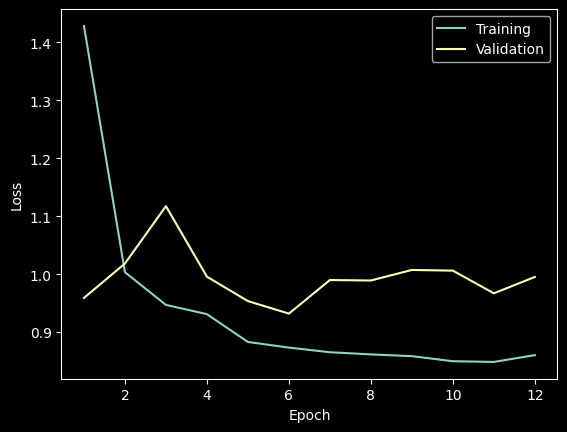

In [3]:
train = windows["split"].eq("train").to_numpy()
val = windows["split"].eq("val").to_numpy()
y = encode_labels(windows["true_label"])
classes = np.arange(len(LABELS))
weights = compute_class_weight("balanced", classes=classes, y=y[train])

normalize = keras.layers.Normalization()
normalize.adapt(x[train])
classifier = keras.Sequential([
    keras.Input(shape=(x.shape[1],)),
    normalize,
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(len(LABELS), activation="softmax"),
])
classifier.compile(optimizer="adam", loss="sparse_categorical_crossentropy")
history = classifier.fit(
    x[train], y[train],
    validation_data=(x[val], y[val]),
    class_weight=dict(enumerate(weights)),
    epochs=40, batch_size=32, verbose=2,
    callbacks=[keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=6, restore_best_weights=True
    )],
)

for key, label in [("loss", "Training"), ("val_loss", "Validation")]:
    values = history.history[key]
    plt.plot(range(1, len(values) + 1), values, label=label)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.savefig(FIGURES_DIR / "transfer_learning_loss.png", dpi=200, bbox_inches="tight")
plt.show()

## Compare the three models

Average window probabilities within each recording, then average across recordings to make one prediction per patient. Report validation separately from the held-out test comparison. **Present recall** tells us how many patients with the Present label the model caught. **Macro-F1** gives all three labels equal weight.

In [4]:
transfer_probs = classifier.predict(x, batch_size=128, verbose=0)
predictions = {
    **baseline_predictions,
    "YAMNet transfer CNN": make_predictions_table(windows, transfer_probs),
}

predictions["YAMNet transfer CNN"].to_csv(outputs / "yamnet_window_predictions.csv", index=False)

def compare(split):
    rows, by_model = [], {}
    for name, table in predictions.items():
        patients = aggregate_patients(table[table["split"].eq(split)], "recording_mean")
        by_model[name] = patients
        scores = metrics(patients)
        target = patients["true_label"].to_numpy()[:, None] == np.array(LABELS)
        auc = roc_auc_score(target, patients[PROBS].to_numpy(), average="macro")
        rows.append({
            "Model": name,
            "Patients": scores["n_subjects"],
            "Accuracy": scores["accuracy"],
            "Macro-F1": scores["macro_f1"],
            "Present recall": scores["recall_present"],
            "Macro ROC-AUC": auc,
        })
    return pd.DataFrame(rows).set_index("Model"), by_model

validation, _ = compare("val")
print("Validation patients")
display(validation.round(3))

Validation patients


,Patients,Accuracy,Macro-F1,Present recall,Macro ROC-AUC
Model,,,,,
Random Forest,141,0.780,0.619,0.481,0.763
Original CNN,141,0.879,0.784,0.704,0.905
YAMNet transfer CNN,141,0.695,0.597,0.630,0.814


Held-out test patients


,Patients,Accuracy,Macro-F1,Present recall,Macro ROC-AUC
Model,,,,,
Random Forest,142,0.718,0.520,0.370,0.766
Original CNN,142,0.824,0.677,0.667,0.896
YAMNet transfer CNN,142,0.690,0.519,0.519,0.781


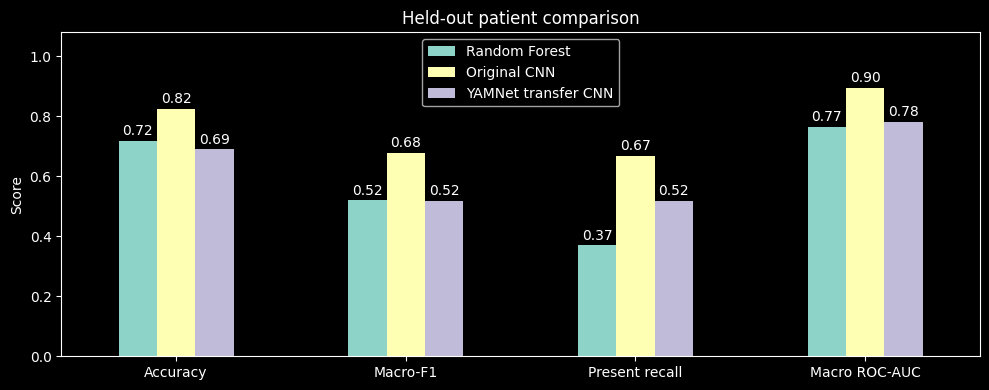

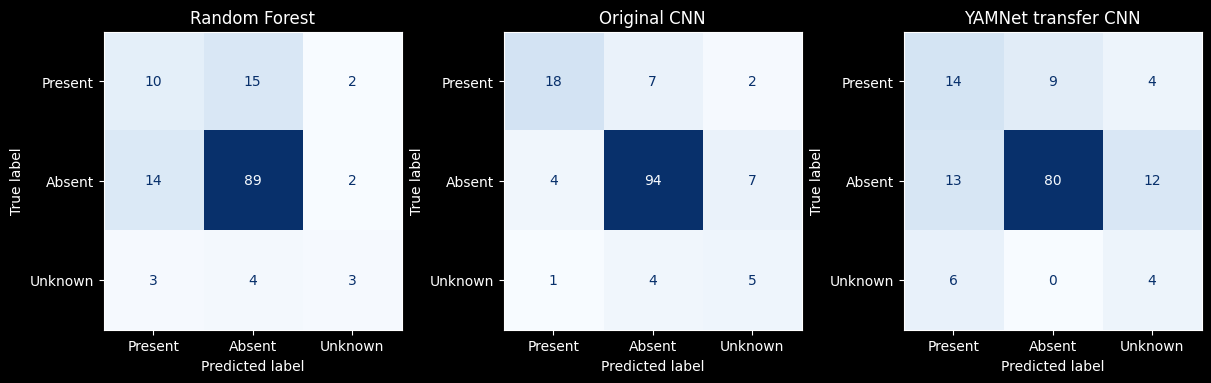

In [5]:
test, test_patients = compare("test")
print("Held-out test patients")
display(test.round(3))

columns = ["Accuracy", "Macro-F1", "Present recall", "Macro ROC-AUC"]
ax = test[columns].T.plot.bar(rot=0, ylim=(0, 1.08), figsize=(10, 4))
ax.set(title="Held-out patient comparison", ylabel="Score")
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", padding=2)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "transfer_learning_comparison.png", dpi=200)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
for ax, (name, patients) in zip(axes, test_patients.items()):
    ConfusionMatrixDisplay.from_predictions(
        patients["true_label"], patients["pred_label"],
        labels=LABELS, cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(name)
fig.savefig(FIGURES_DIR / "transfer_learning_confusion_matrices.png", dpi=200)
plt.show()

## CNN versus transfer learning ROC curves

Compare the original CNN with the frozen YAMNet transfer approach on the same held-out test patients. Each panel shows one-versus-rest ROC curves for Present, Absent, and Unknown after giving each recording equal weight.

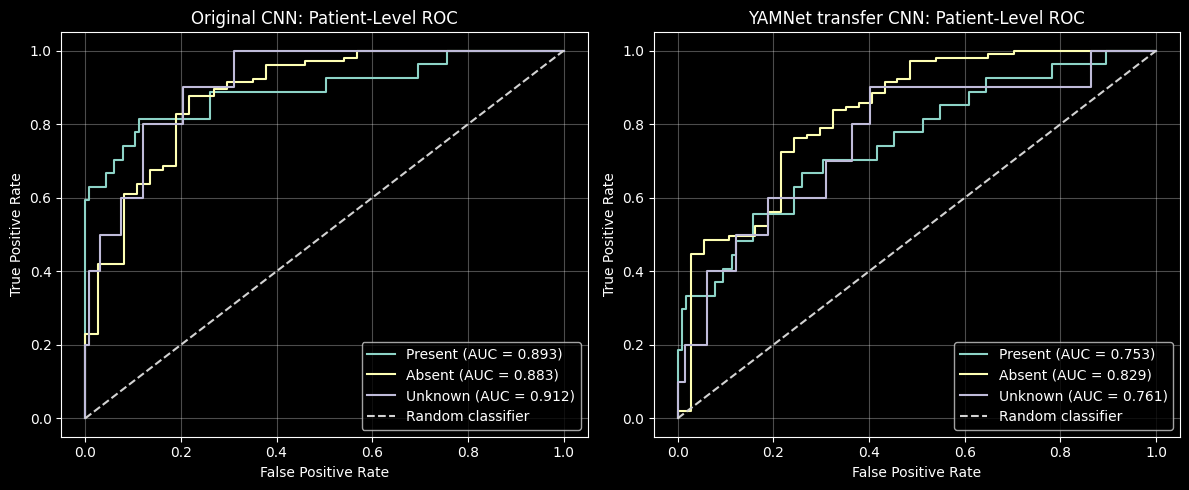

In [ ]:
from sklearn.metrics import roc_curve, auc

transfer_windows = pd.read_csv(
    outputs / "yamnet_window_predictions.csv",
    dtype={"subject_id": str, "recording_id": str}
)
pd.testing.assert_frame_equal(reference, window_index(transfer_windows))
roc_predictions = {
    name: aggregate_patients(table.loc[table["split"].eq("test")], "recording_mean")
    for name, table in [
        ("Original CNN", baseline_predictions["Original CNN"]),
        ("YAMNet transfer CNN", transfer_windows),
    ]
}
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, patients) in zip(axes, roc_predictions.items()):
    for label, probability_column in zip(LABELS, PROBS):
        fpr, tpr, _ = roc_curve(patients["true_label"].eq(label), patients[probability_column])
        ax.plot(fpr, tpr, label=f"{label} (AUC = {auc(fpr, tpr):.3f})")
    ax.plot([0, 1], [0, 1], color="lightgray", linestyle="--", label="Random classifier")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(name + ": Patient-Level ROC")
    ax.grid(alpha=0.3)
    ax.legend(loc="lower right")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "cnn_vs_transfer_learning_roc_curves.png", dpi=300)
plt.show()
plt.close(fig)

The held-out test comparison shows that the frozen YAMNet approach did not outperform the repo's original CNN on these patients. It reached 0.690 accuracy and 0.519 macro-F1 versus 0.824 accuracy and 0.677 macro-F1 for the original CNN, so the pretrained backbone alone was not enough in this setup. To isolate the benefit of pretraining itself, a separate experiment would compare the same architecture and input pipeline with pretrained and random weights.